# Sensitivity analysis 3: diagnosis-selected oxygen saturation Scale 2

Compare a matched **Scale 1 baseline** with **Scale 2 for patients whose `Dg #1` equals 10**, retaining Scale 1 for everyone else. This study-specific diagnostic selection rule is applied in both prehospital and hospital settings. Missing or nonnumeric diagnosis codes do not equal 10 and retain Scale 1; their counts are shown for review.

Consciousness remains at the baseline GCS cutoff 15: this notebook does not combine the GCS < 13 sensitivity change with oxygen-scale selection. Other NEWS2 parameters and outcome definitions are unchanged. Both variants use identical patients/folds and repeat threshold selection separately.

## Oxygen saturation Scale 2

| Saturation (%) | Component points |
| --- | --- |
| ≤83 | 3 |
| 84–85 | 2 |
| 86–87 | 1 |
| 88–92 | 0 |
| ≥93 on room air | 0 |
| 93–94 on supplemental oxygen | 1 |
| 95–96 on supplemental oxygen | 2 |
| ≥97 on supplemental oxygen | 3 |

The separate supplemental-oxygen component still contributes 2 points when retained. Its observed status is used to select the Scale 2 saturation band even when that separate component is omitted from a subset. Thus the saturation component is interpreted conditional on observed oxygen status and the study's diagnosis rule. Fractional saturations use lower-bound chart intervals: <84, [84,86), [86,88), [88,93), and on oxygen [93,95), [95,97), ≥97; no rounding is applied. Scale 1 uses the existing implementation.

Source: [Royal College of Physicians NEWS2 observation chart (2022)](https://www.rcp.ac.uk/media/eczf5mvm/news2-chart-3_news-observation-chart_2022_0_0.pdf). The chart specifies Scale 2 for a prescribed target range of 88–92%; `Dg #1 == 10` is the user-specified study proxy, not a clinical eligibility rule inferred by this code.

## Execution and outputs

Run locally with the original dataset. No analyses or tests were executed while preparing this notebook. Missing GCS and FiO2 handling is inherited from `sensitivity_helpers.py`; baseline and modified results use the same eligibility rules. Results are checkpointed per subset with dataset/scoring fingerprints. This is a separate analysis without bootstrap intervals.


## 1. Setup

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Supports starting Jupyter from the repository root or this notebook folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "functions" / "news2_scale_deconstruction.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter from the NEWS2 repository or sensitivity folder.")
SENSITIVITY_DIR = ROOT / "sensitivity analisis"
for location in (ROOT, SENSITIVITY_DIR):
    if str(location) not in sys.path:
        sys.path.insert(0, str(location))

from sensitivity_helpers import FEATURES, load_original_data, assign_grouped_folds
from oxygen_scale_sensitivity_helpers import (
    prepare_oxygen_cohort, oxygen_components, run_oxygen_subset_search,
    plot_oxygen_delta_auc_by_size,
)
from functions.news2_auc_shapley import plot_news2_auc_attribution
from functions.news2_auc_dominance import plot_news2_auc_dominance

DATA_PATH = ROOT / "data" / "NEWs2.csv"
RANDOM_STATE = 42
N_OUTER_FOLDS = 10
N_JOBS = 1
OUTPUT_DIR = ROOT / "data" / "outputs" / "sensitivity" / "oxygen_scale2_diagnosis10"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Prepare matched cohorts and audit scale selection

In [2]:
raw_data = load_original_data(DATA_PATH)
cohorts = {}
audit = []
for setting, suffix in (("Prehospital", "1"), ("Hospital", "H")):
    cohort = prepare_oxygen_cohort(raw_data, suffix)
    baseline_points = oxygen_components(cohort, use_diagnosis_scale2=False)
    modified_points = oxygen_components(cohort, use_diagnosis_scale2=True)
    cohorts[setting] = cohort
    audit.append({
        "cohort": setting, "eligible_patients": len(cohort),
        "diagnosis_10_scale2": int(cohort["uses_scale2"].sum()),
        "missing_or_nonnumeric_diagnosis": int(cohort["diagnosis_code"].isna().sum()),
        "changed_saturation_points": int(baseline_points["blod_oxy"].ne(modified_points["blod_oxy"]).sum()),
        "baseline_mean_news2": baseline_points.sum(axis=1).mean(),
        "modified_mean_news2": modified_points.sum(axis=1).mean(),
    })
scale_audit = pd.DataFrame(audit)
scale_audit.to_csv(OUTPUT_DIR / "scale_selection_audit.csv", index=False)
scale_audit

,cohort,eligible_patients,diagnosis_10_scale2,missing_or_nonnumeric_diagnosis,changed_saturation_points,baseline_mean_news2,modified_mean_news2
0,Prehospital,17970,1208,0,618,4.823484,4.777574
1,Hospital,16852,1121,0,850,4.182412,4.196831


## 3. Matched cross-validation

Each variant evaluates 127 subsets, with a meaningful 127-subset progress bar. The same folded cohort is passed to both variants. The explicitly supplied component scores prevent the standard search from silently reverting to Scale 1.

In [3]:
def run_matched_oxygen_experiment(setting, outcome):
    folded = assign_grouped_folds(
        cohorts[setting], outcome, N_OUTER_FOLDS, RANDOM_STATE,
    )
    slug = f"{setting.lower()}_{outcome.lower()}"
    folded[["#ID", "_source_patient", outcome, "cv_fold", "diagnosis_code", "uses_scale2"]].to_csv(
        OUTPUT_DIR / f"{slug}_fold_assignments.csv", index=False,
    )
    results = {}
    for variant in ("baseline", "diagnosis_scale2"):
        results[variant] = run_oxygen_subset_search(
            folded, outcome, variant,
            results_path=OUTPUT_DIR / f"{slug}_{variant}_results.csv",
            experiment_id=f"{slug}_{variant}_{N_OUTER_FOLDS}fold_seed{RANDOM_STATE}",
            n_jobs=N_JOBS,
        )
    return results

experiments = {}

### Prehospital — 30-day mortality

In [4]:
experiments[('Prehospital', 'M30D')] = run_matched_oxygen_experiment('Prehospital', 'M30D')
results_m30d_pre = experiments[('Prehospital', 'M30D')]["diagnosis_scale2"]
results_m30d_pre.sort_values(["balanced_accuracy", "auc"], ascending=False).head(15)

prehospital_m30d_baseline_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

prehospital_m30d_diagnosis_scale2_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp,oxygen_scoring_variant
35,prehospital_m30d_diagnosis_scale2_10fold_seed42,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,"[""blod_oxy"", ""oxigen"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.759455,"[{""auc"":0.8419597048,""balanced_accuracy"":0.788...",0,1,1,0,0,1,0,diagnosis_scale2
8,prehospital_m30d_diagnosis_scale2_10fold_seed42,blod_oxy|consciousness,blod_oxy + consciousness,"[""blod_oxy"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.755775,"[{""auc"":0.8271430218,""balanced_accuracy"":0.775...",0,1,0,0,0,1,0,diagnosis_scale2
108,prehospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousness,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.751872,"[{""auc"":0.8373710152,""balanced_accuracy"":0.770...",1,1,1,1,0,1,0,diagnosis_scale2
67,prehospital_m30d_diagnosis_scale2_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness,blod_oxy + oxigen + blod_pres + consciousness,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.751238,"[{""auc"":0.8426918199,""balanced_accuracy"":0.775...",0,1,1,1,0,1,0,diagnosis_scale2
19,prehospital_m30d_diagnosis_scale2_10fold_seed42,oxigen|consciousness,oxigen + consciousness,"[""oxigen"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.750769,"[{""auc"":0.7978771546,""balanced_accuracy"":0.780...",0,0,1,0,0,1,0,diagnosis_scale2
28,prehospital_m30d_diagnosis_scale2_10fold_seed42,blod_oxy|blod_pres|consciousness,blod_oxy + blod_pres + consciousness,"[""blod_oxy"", ""blod_pres"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.749593,"[{""auc"":0.8306537153,""balanced_accuracy"":0.768...",0,1,0,1,0,1,0,diagnosis_scale2
85,prehospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_oxy|oxigen|consciousness,resp_rate + blod_oxy + oxigen + consciousness,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.749474,"[{""auc"":0.8347106128,""balanced_accuracy"":0.762...",1,1,1,0,0,1,0,diagnosis_scale2
70,prehospital_m30d_diagnosis_scale2_10fold_seed42,blod_oxy|oxigen|consciousness|temp,blod_oxy + oxigen + consciousness + temp,"[""blod_oxy"", ""oxigen"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.748951,"[{""auc"":0.8385153052,""balanced_accuracy"":0.777...",0,1,1,0,0,1,1,diagnosis_scale2
99,prehospital_m30d_diagnosis_scale2_10fold_seed42,blod_oxy|oxigen|blod_pres|consciousness|temp,blod_oxy + oxigen + blod_pres + consciousness ...,"[""blod_oxy"", ""oxigen"", ""blod_pres"", ""conscious...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.747010,"[{""auc"":0.8372225745,""balanced_accuracy"":0.768...",0,1,1,1,0,1,1,diagnosis_scale2
121,prehospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousn...,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",6,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.746791,"[{""auc"":0.8349109356,""balanced_accuracy"":0.755...",1,1,1,1,0,1,1,diagnosis_scale2


### Prehospital — ICU admission

In [7]:
experiments[('Prehospital', 'UVI')] = run_matched_oxygen_experiment('Prehospital', 'UVI')
results_uvi_pre = experiments[('Prehospital', 'UVI')]["diagnosis_scale2"]
results_uvi_pre.sort_values(["balanced_accuracy", "auc"], ascending=False).head(15)

prehospital_uvi_baseline_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

prehospital_uvi_diagnosis_scale2_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp,oxygen_scoring_variant
42,prehospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|blod_pres|consciousness,oxigen + blod_pres + consciousness,"[""oxigen"", ""blod_pres"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.727170,"[{""auc"":0.7784556282,""balanced_accuracy"":0.753...",0,0,1,1,0,1,0,diagnosis_scale2
12,prehospital_uvi_diagnosis_scale2_10fold_seed42,blod_pres|consciousness,blod_pres + consciousness,"[""blod_pres"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.725793,"[{""auc"":0.7679240122,""balanced_accuracy"":0.753...",0,0,0,1,0,1,0,diagnosis_scale2
8,prehospital_uvi_diagnosis_scale2_10fold_seed42,blod_oxy|consciousness,blod_oxy + consciousness,"[""blod_oxy"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.724360,"[{""auc"":0.7986746898,""balanced_accuracy"":0.756...",0,1,0,0,0,1,0,diagnosis_scale2
2,prehospital_uvi_diagnosis_scale2_10fold_seed42,consciousness,consciousness,"[""consciousness""]",1,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.722260,"[{""auc"":0.7650135515,""balanced_accuracy"":0.765...",0,0,0,0,0,1,0,diagnosis_scale2
35,prehospital_uvi_diagnosis_scale2_10fold_seed42,blod_oxy|oxigen|consciousness,blod_oxy + oxigen + consciousness,"[""blod_oxy"", ""oxigen"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.721264,"[{""auc"":0.8005134645,""balanced_accuracy"":0.751...",0,1,1,0,0,1,0,diagnosis_scale2
19,prehospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|consciousness,oxigen + consciousness,"[""oxigen"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.722281,"[{""auc"":0.7811634383,""balanced_accuracy"":0.765...",0,0,1,0,0,1,0,diagnosis_scale2
28,prehospital_uvi_diagnosis_scale2_10fold_seed42,blod_oxy|blod_pres|consciousness,blod_oxy + blod_pres + consciousness,"[""blod_oxy"", ""blod_pres"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.718563,"[{""auc"":0.7905997464,""balanced_accuracy"":0.740...",0,1,0,1,0,1,0,diagnosis_scale2
45,prehospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|consciousness|temp,oxigen + consciousness + temp,"[""oxigen"", ""consciousness"", ""temp""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.718435,"[{""auc"":0.7830494567,""balanced_accuracy"":0.746...",0,0,1,0,0,1,1,diagnosis_scale2
15,prehospital_uvi_diagnosis_scale2_10fold_seed42,consciousness|temp,consciousness + temp,"[""consciousness"", ""temp""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.718067,"[{""auc"":0.7746773752,""balanced_accuracy"":0.752...",0,0,0,0,0,1,1,diagnosis_scale2
70,prehospital_uvi_diagnosis_scale2_10fold_seed42,blod_oxy|oxigen|consciousness|temp,blod_oxy + oxigen + consciousness + temp,"[""blod_oxy"", ""oxigen"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.717672,"[{""auc"":0.7986249596,""balanced_accuracy"":0.736...",0,1,1,0,0,1,1,diagnosis_scale2


### Hospital — 30-day mortality

In [10]:
experiments[('Hospital', 'M30D')] = run_matched_oxygen_experiment('Hospital', 'M30D')
results_m30d_hosp = experiments[('Hospital', 'M30D')]["diagnosis_scale2"]
results_m30d_hosp.sort_values(["balanced_accuracy", "auc"], ascending=False).head(15)

hospital_m30d_baseline_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

hospital_m30d_diagnosis_scale2_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp,oxygen_scoring_variant
92,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|blod_pres|consciousness,resp_rate + oxigen + blod_pres + consciousness,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""consciou...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.797820,"[{""auc"":0.8542004162,""balanced_accuracy"":0.785...",1,0,1,1,0,1,0,diagnosis_scale2
108,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_oxy|oxigen|blod_pres|consciousness,resp_rate + blod_oxy + oxigen + blod_pres + co...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""blod_pres...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.796517,"[{""auc"":0.856246883,""balanced_accuracy"":0.7944...",1,1,1,1,0,1,0,diagnosis_scale2
116,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|blod_pres|heart_rate|consciou...,resp_rate + oxigen + blod_pres + heart_rate + ...,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""heart_ra...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.796489,"[{""auc"":0.8491633562,""balanced_accuracy"":0.787...",1,0,1,1,1,1,0,diagnosis_scale2
24,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|consciousness,resp_rate + consciousness,"[""resp_rate"", ""consciousness""]",2,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.795473,"[{""auc"":0.7999638859,""balanced_accuracy"":0.783...",1,0,0,0,0,1,0,diagnosis_scale2
60,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|consciousness,resp_rate + oxigen + consciousness,"[""resp_rate"", ""oxigen"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.795299,"[{""auc"":0.8374211078,""balanced_accuracy"":0.783...",1,0,1,0,0,1,0,diagnosis_scale2
95,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|consciousness|temp,resp_rate + oxigen + consciousness + temp,"[""resp_rate"", ""oxigen"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.794539,"[{""auc"":0.8468709694,""balanced_accuracy"":0.787...",1,0,1,0,0,1,1,diagnosis_scale2
112,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_oxy|oxigen|heart_rate|conscious...,resp_rate + blod_oxy + oxigen + heart_rate + c...,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""heart_rat...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.793726,"[{""auc"":0.8368587594,""balanced_accuracy"":0.785...",1,1,1,0,1,1,0,diagnosis_scale2
85,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_oxy|oxigen|consciousness,resp_rate + blod_oxy + oxigen + consciousness,"[""resp_rate"", ""blod_oxy"", ""oxigen"", ""conscious...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.794025,"[{""auc"":0.8418098334,""balanced_accuracy"":0.790...",1,1,1,0,0,1,0,diagnosis_scale2
118,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|heart_rate|consciousness|temp,resp_rate + oxigen + heart_rate + consciousnes...,"[""resp_rate"", ""oxigen"", ""heart_rate"", ""conscio...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.792788,"[{""auc"":0.8456293315,""balanced_accuracy"":0.778...",1,0,1,0,1,1,1,diagnosis_scale2
53,hospital_m30d_diagnosis_scale2_10fold_seed42,resp_rate|blod_pres|consciousness,resp_rate + blod_pres + consciousness,"[""resp_rate"", ""blod_pres"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.792411,"[{""auc"":0.825534403,""balanced_accuracy"":0.7834...",1,0,0,1,0,1,0,diagnosis_scale2


### Hospital — ICU admission

In [11]:
experiments[('Hospital', 'UVI')] = run_matched_oxygen_experiment('Hospital', 'UVI')
results_uvi_hosp = experiments[('Hospital', 'UVI')]["diagnosis_scale2"]
results_uvi_hosp.sort_values(["balanced_accuracy", "auc"], ascending=False).head(15)

hospital_uvi_baseline_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

hospital_uvi_diagnosis_scale2_10fold_seed42: subsets:   0%|          | 0/127 [00:00<?, ?subset/s]

,experiment_id,subset_key,subset_label,features_json,n_features,n_outer_folds,n_inner_folds,scoring_method,threshold_selection,reference_threshold,...,inner_best_balanced_accuracy_mean,outer_fold_metrics_json,resp_rate,blod_oxy,oxigen,blod_pres,heart_rate,consciousness,temp,oxygen_scoring_variant
92,hospital_uvi_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|blod_pres|consciousness,resp_rate + oxigen + blod_pres + consciousness,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""consciou...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.775414,"[{""auc"":0.8166514538,""balanced_accuracy"":0.768...",1,0,1,1,0,1,0,diagnosis_scale2
42,hospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|blod_pres|consciousness,oxigen + blod_pres + consciousness,"[""oxigen"", ""blod_pres"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.773415,"[{""auc"":0.8313465007,""balanced_accuracy"":0.755...",0,0,1,1,0,1,0,diagnosis_scale2
75,hospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|blod_pres|heart_rate|consciousness,oxigen + blod_pres + heart_rate + consciousness,"[""oxigen"", ""blod_pres"", ""heart_rate"", ""conscio...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.775051,"[{""auc"":0.8346924075,""balanced_accuracy"":0.751...",0,0,1,1,1,1,0,diagnosis_scale2
116,hospital_uvi_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|blod_pres|heart_rate|consciou...,resp_rate + oxigen + blod_pres + heart_rate + ...,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""heart_ra...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.772455,"[{""auc"":0.8156012185,""balanced_accuracy"":0.756...",1,0,1,1,1,1,0,diagnosis_scale2
103,hospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|blod_pres|heart_rate|consciousness|temp,oxigen + blod_pres + heart_rate + consciousnes...,"[""oxigen"", ""blod_pres"", ""heart_rate"", ""conscio...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.772296,"[{""auc"":0.8273943716,""balanced_accuracy"":0.749...",0,0,1,1,1,1,1,diagnosis_scale2
115,hospital_uvi_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|blod_pres|consciousness|temp,resp_rate + oxigen + blod_pres + consciousness...,"[""resp_rate"", ""oxigen"", ""blod_pres"", ""consciou...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.771632,"[{""auc"":0.8144451348,""balanced_accuracy"":0.762...",1,0,1,1,0,1,1,diagnosis_scale2
96,hospital_uvi_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|heart_rate|consciousness,resp_rate + oxigen + heart_rate + consciousness,"[""resp_rate"", ""oxigen"", ""heart_rate"", ""conscio...",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.771071,"[{""auc"":0.8268060199,""balanced_accuracy"":0.770...",1,0,1,0,1,1,0,diagnosis_scale2
77,hospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|heart_rate|consciousness|temp,oxigen + heart_rate + consciousness + temp,"[""oxigen"", ""heart_rate"", ""consciousness"", ""temp""]",4,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.770564,"[{""auc"":0.8424262086,""balanced_accuracy"":0.756...",0,0,1,0,1,1,1,diagnosis_scale2
46,hospital_uvi_diagnosis_scale2_10fold_seed42,oxigen|heart_rate|consciousness,oxigen + heart_rate + consciousness,"[""oxigen"", ""heart_rate"", ""consciousness""]",3,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.770557,"[{""auc"":0.8520501584,""balanced_accuracy"":0.762...",0,0,1,0,1,1,0,diagnosis_scale2
118,hospital_uvi_diagnosis_scale2_10fold_seed42,resp_rate|oxigen|heart_rate|consciousness|temp,resp_rate + oxigen + heart_rate + consciousnes...,"[""resp_rate"", ""oxigen"", ""heart_rate"", ""conscio...",5,10,9,partial_news2_sum,mean_inner_fold_balanced_accuracy,5.0,...,0.768601,"[{""auc"":0.8259551093,""balanced_accuracy"":0.760...",1,0,1,0,1,1,1,diagnosis_scale2


## 4. Compare all matched subsets

Differences are diagnosis-selected Scale 2 minus the all-Scale 1 baseline. Subsets without saturation must remain unchanged.

In [12]:
comparisons = []
for (setting, outcome), variants in experiments.items():
    metrics = ["subset_key", "subset_label", "n_features", "auc", "balanced_accuracy"]
    paired = variants["baseline"][metrics].merge(
        variants["diagnosis_scale2"][["subset_key", "auc", "balanced_accuracy"]],
        on="subset_key", suffixes=("_baseline", "_scale2"), validate="one_to_one",
    )
    paired["cohort"] = setting
    paired["outcome"] = outcome
    paired["delta_auc"] = paired["auc_scale2"] - paired["auc_baseline"]
    paired["delta_ba"] = paired["balanced_accuracy_scale2"] - paired["balanced_accuracy_baseline"]
    unaffected = ~paired["subset_key"].str.split("|").map(lambda names: "blod_oxy" in names)
    if not np.allclose(paired.loc[unaffected, ["delta_auc", "delta_ba"]], 0, atol=1e-12):
        raise ValueError("Subsets without saturation changed; inspect scoring/fold alignment.")
    comparisons.append(paired)
comparison = pd.concat(comparisons, ignore_index=True)
comparison.to_csv(OUTPUT_DIR / "scale2_vs_baseline_all_subsets.csv", index=False)
comparison.loc[comparison["n_features"].eq(7)]

,subset_key,subset_label,n_features,auc_baseline,balanced_accuracy_baseline,auc_scale2,balanced_accuracy_scale2,cohort,outcome,delta_auc,delta_ba
126,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.814682,0.734846,0.814747,0.738542,Prehospital,M30D,0.000064,0.003696
253,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.758032,0.695546,0.760099,0.697491,Prehospital,UVI,0.002067,0.001945
380,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.861442,0.783903,0.859092,0.782412,Hospital,M30D,-0.002351,-0.001490
507,resp_rate|blod_oxy|oxigen|blod_pres|heart_rate...,resp_rate + blod_oxy + oxigen + blod_pres + he...,7,0.801236,0.752258,0.800037,0.750264,Hospital,UVI,-0.001199,-0.001994


## 5. AUC changes by subset size: subsets containing oxygen saturation

The 64 saturation-containing subsets are grouped by sizes 1–7, with counts **1, 6, 15, 20, 15, 6, 1**. Each point represents one matched subset's AUC change. Sizes 1 and 7 show one point; sizes 2–6 show boxes with all observations. Boxes show median and interquartile range, with 1.5-IQR whiskers. These are distributions across combinations, not confidence intervals. Positive changes favor diagnosis-selected Scale 2. All four plots share a vertical range and Turbo subset-size colors.

### Prehospital — M30D

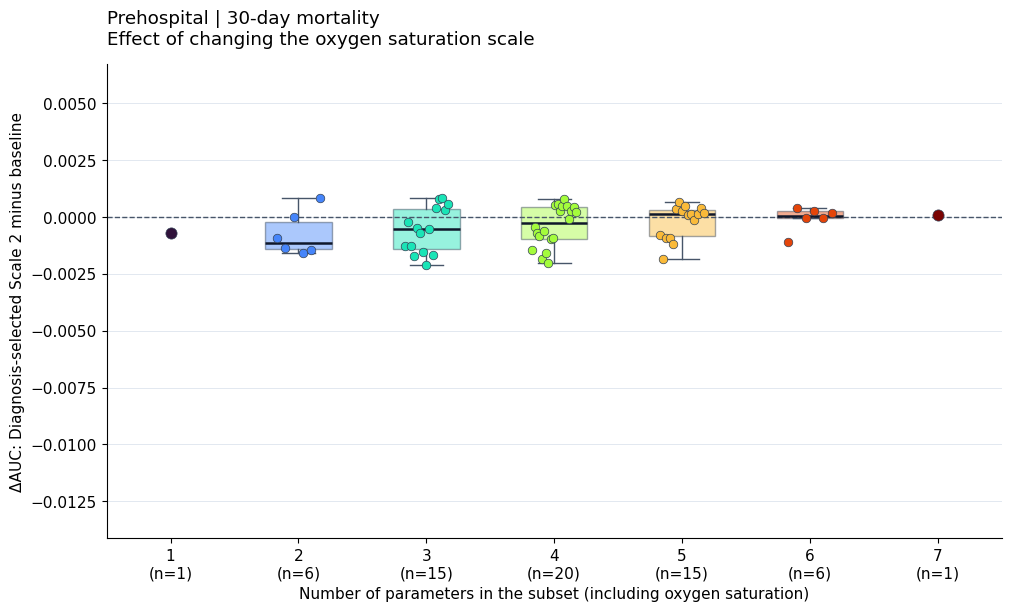

In [13]:
figure = plot_oxygen_delta_auc_by_size(
    comparison, setting='Prehospital', outcome='M30D',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

### Prehospital — UVI

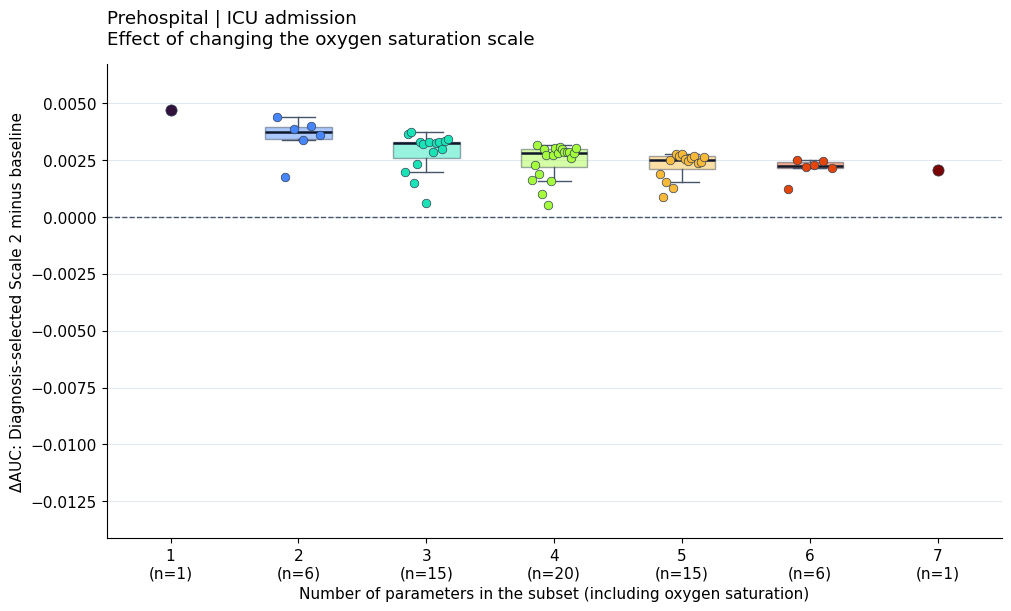

In [14]:
figure = plot_oxygen_delta_auc_by_size(
    comparison, setting='Prehospital', outcome='UVI',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

### Hospital — M30D

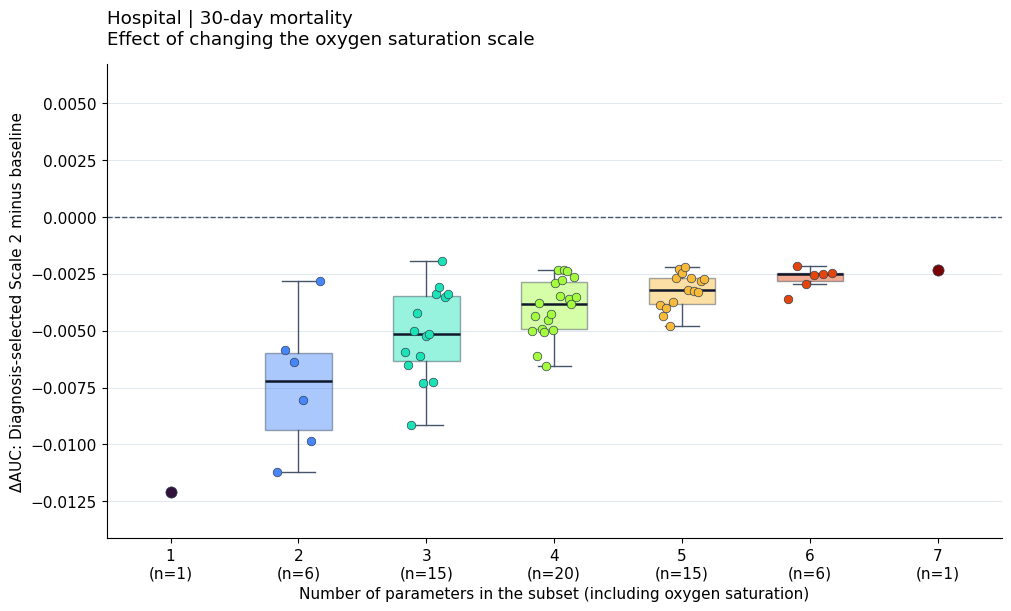

In [15]:
figure = plot_oxygen_delta_auc_by_size(
    comparison, setting='Hospital', outcome='M30D',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

### Hospital — UVI

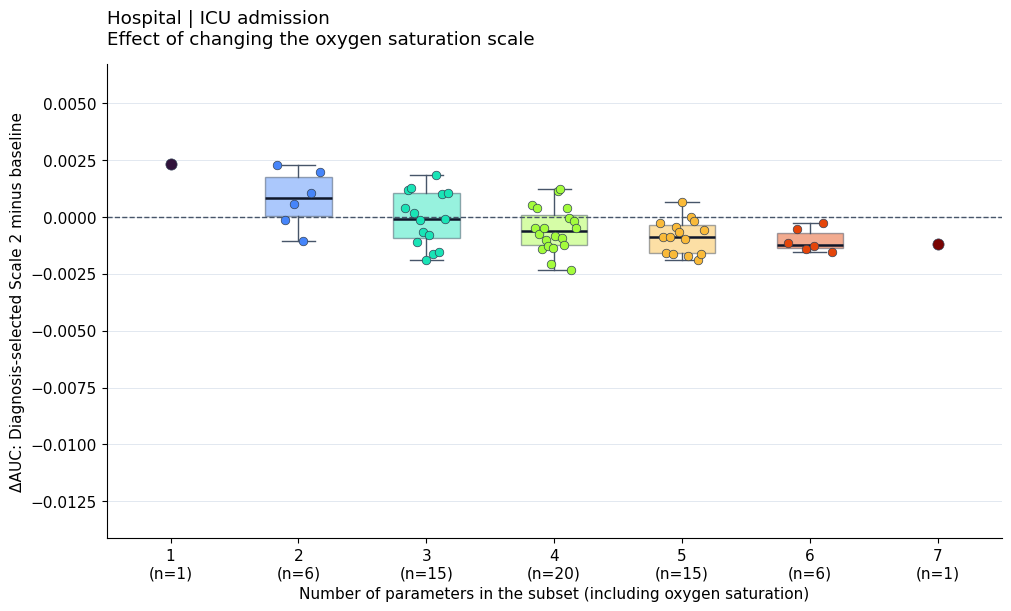

In [16]:
figure = plot_oxygen_delta_auc_by_size(
    comparison, setting='Hospital', outcome='UVI',
    output_dir=OUTPUT_DIR / "delta_auc_by_subset_size",
)
plt.show()
plt.close(figure)

## Interpretation

Assess full-score AUC and BA differences, the distribution of AUC changes across saturation-containing subsets, and shifts in attribution or dominance. Scale 2 changes saturation points only for diagnosis code 10; cohorts without such patients should be unchanged. These are descriptive paired comparisons, without uncertainty intervals or significance testing. AUC may improve or worsen; no result is assumed before execution.